# Decision Tree Classification

- **Entropy** measures uncertainty in a node.
- **Information gain** measures the reduction in entropy after a split.
- **Gini impurity** measures how often a randomly selected sample would be incorrectly classified.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [2]:
def entropy(labels):
    """Return base-2 entropy for a one-dimensional label array."""
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()
    return -np.sum(probabilities * np.log2(probabilities))


def gini_impurity(labels):
    """Return Gini impurity for a one-dimensional label array."""
    _, counts = np.unique(labels, return_counts=True)
    probabilities = counts / counts.sum()
    return 1 - np.sum(probabilities**2)


def information_gain(parent, left, right):
    """Return entropy reduction for a binary split."""
    parent_size = len(parent)
    weighted_children = (
        len(left) / parent_size * entropy(left)
        + len(right) / parent_size * entropy(right)
    )
    return entropy(parent) - weighted_children

In [3]:
# A pure binary split has maximum information gain.
parent_labels = np.array([0, 0, 0, 1, 1, 1])
left_labels = np.array([0, 0, 0])
right_labels = np.array([1, 1, 1])

manual_criteria = pd.DataFrame(
    {
        "Measure": ["Parent entropy", "Parent Gini", "Information gain"],
        "Value": [
            entropy(parent_labels),
            gini_impurity(parent_labels),
            information_gain(parent_labels, left_labels, right_labels),
        ],
    }
)
manual_criteria.round(4)

,Measure,Value
0,Parent entropy,1.0
1,Parent Gini,0.5
2,Information gain,1.0


In [4]:
# Load and split the classification dataset.
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")
print(f"Classes: {list(data.target_names)}")

Training samples: 455
Testing samples: 114
Classes: [np.str_('malignant'), np.str_('benign')]


In [5]:
# Train trees using Gini impurity and entropy as split criteria.
models = {
    "Gini impurity": DecisionTreeClassifier(
        criterion="gini", max_depth=5, random_state=42
    ),
    "Entropy / information gain": DecisionTreeClassifier(
        criterion="entropy", max_depth=5, random_state=42
    ),
}

results = []
predictions_by_model = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    predictions_by_model[name] = predictions
    results.append(
        {
            "Criterion": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "F1": f1_score(y_test, predictions),
            "Depth": model.get_depth(),
            "Leaves": model.get_n_leaves(),
        }
    )

results_table = pd.DataFrame(results).set_index("Criterion")
results_table.round(4)

,Accuracy,F1,Depth,Leaves
Criterion,,,,
Gini impurity,0.9211,0.9362,5,15
Entropy / information gain,0.9298,0.9429,5,14


In [6]:
# Detailed metrics for the entropy-based tree.
print(
    classification_report(
        y_test,
        predictions_by_model["Entropy / information gain"],
        target_names=data.target_names,
    )
)

              precision    recall  f1-score   support

   malignant       0.87      0.95      0.91        42
      benign       0.97      0.92      0.94        72

    accuracy                           0.93       114
   macro avg       0.92      0.93      0.93       114
weighted avg       0.93      0.93      0.93       114



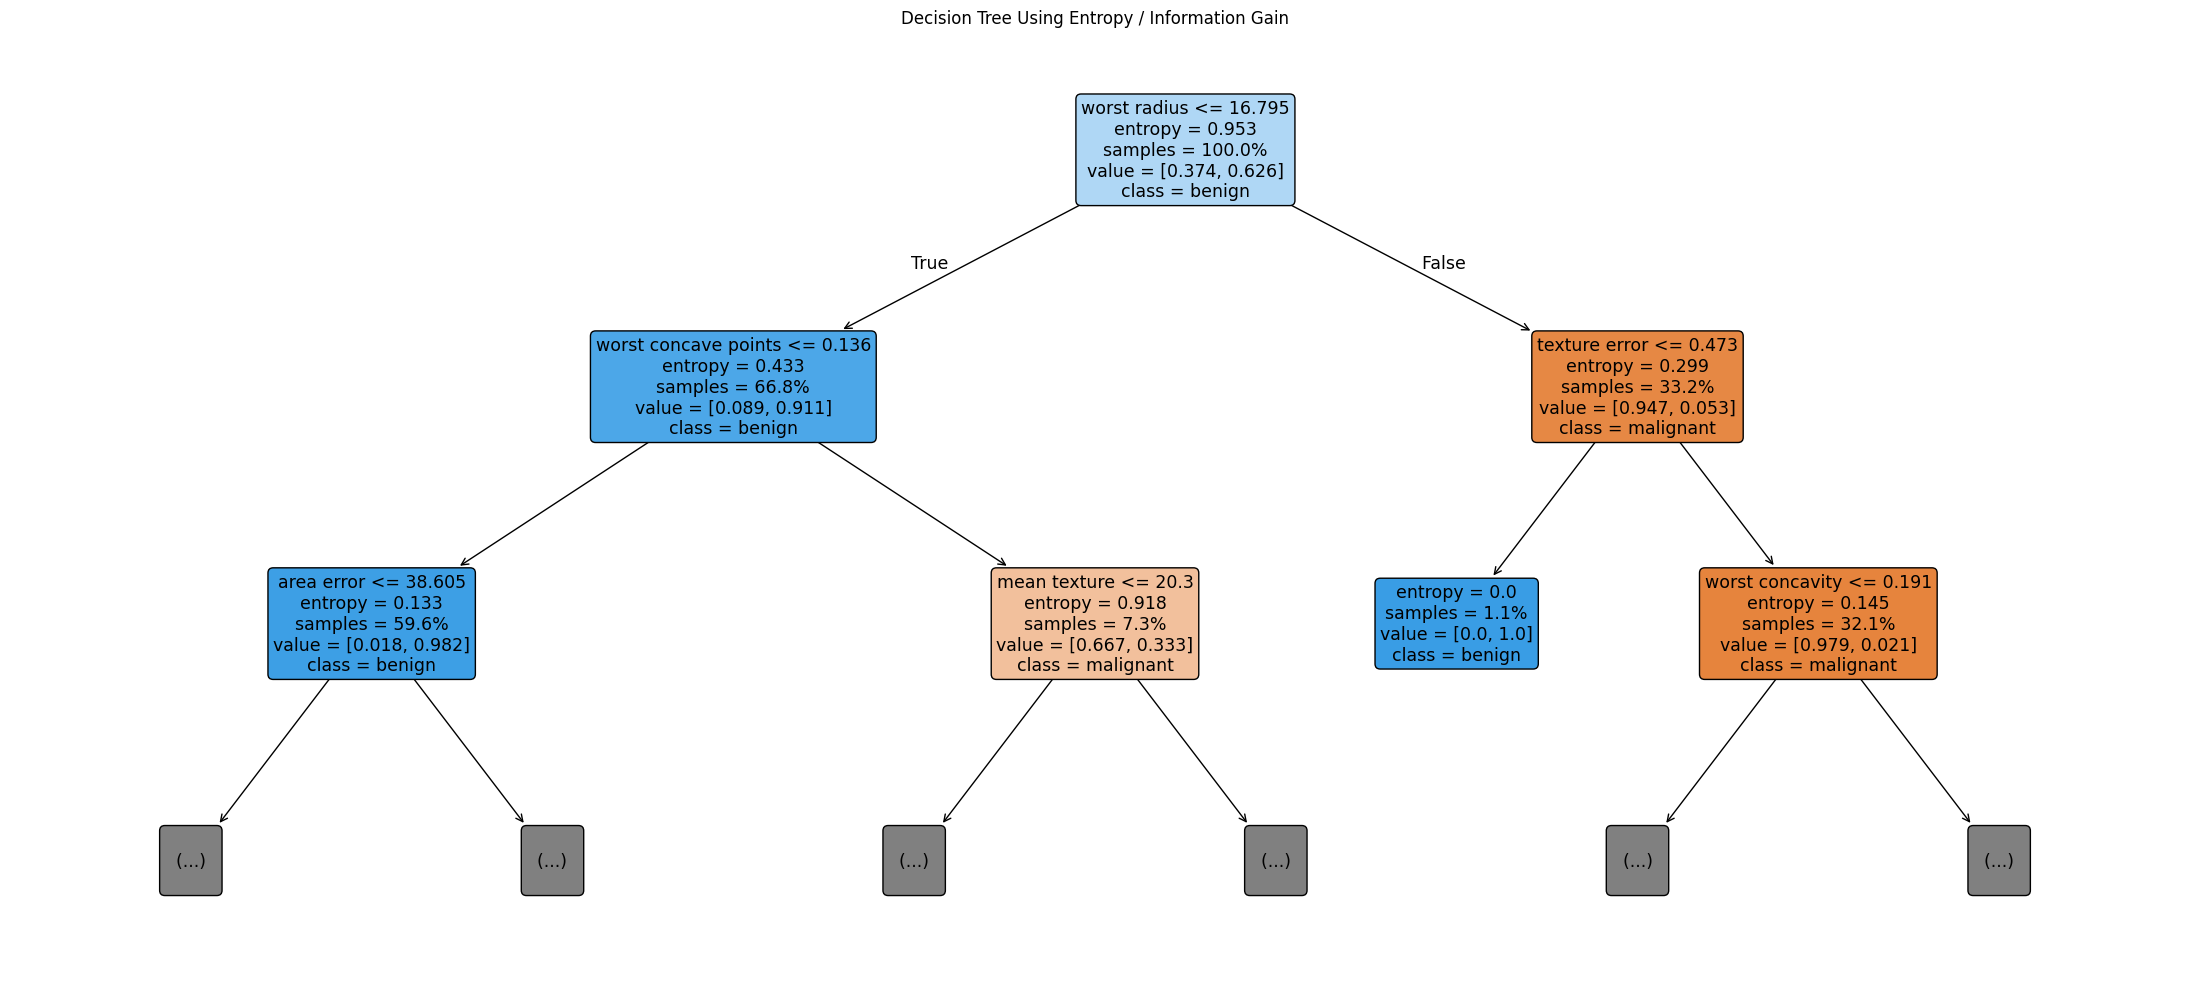

In [7]:
# Visualize the first few levels of the entropy-based tree.
plt.figure(figsize=(22, 10))
plot_tree(
    models["Entropy / information gain"],
    feature_names=X.columns,
    class_names=data.target_names,
    filled=True,
    max_depth=2,
    proportion=True,
    rounded=True,
)
plt.title("Decision Tree Using Entropy / Information Gain")
plt.tight_layout()
plt.show()